# Resumen: variables y gráficos

Este cuaderno resume las herramientas necesarias para trabajar con **variables cualitativas nominales** y **variables cuantitativas**.

El orden será:

1. reconocer el tipo de variable;
2. trabajar primero con variables nominales;
3. construir tablas y gráficos para variables nominales;
4. pasar a variables cuantitativas;
5. agrupar datos cuantitativos en intervalos;
6. construir tablas de frecuencias e histogramas;
7. calcular marcas de clase;
8. utilizar Sturges cuando sea necesario;
9. aplicar herramientas como `groupby()`, porcentajes y ordenamiento.

Los ejemplos son distintos de los ejercicios de la guía.

# 1. Conceptos básicos

## Población

La **población** es el conjunto completo de individuos o elementos que se desea estudiar.

## Muestra

La **muestra** es una parte de la población sobre la cual se recolectan los datos.

## Variable

Una **variable estadística** es una característica que observamos o medimos en cada individuo.

Ejemplos:

- medio de transporte;
- ocupación;
- edad;
- estatura;
- cantidad de hermanos.

# 2. Tipos de variables

En este laboratorio nos concentraremos principalmente en dos tipos.

## Variable cualitativa nominal

Representa **categorías que no poseen un orden natural**.

Ejemplos:

- lenguaje de programación;
- ocupación;
- continente;
- medio de transporte.

## Variable cuantitativa

Representa una característica expresada mediante números.

Ejemplos:

- edad;
- estatura;
- población;
- cantidad de usuarios;
- porcentaje de usuarios.

> Antes de elegir una tabla o un gráfico, debemos identificar el tipo de variable.

# PARTE I: VARIABLES CUALITATIVAS NOMINALES

Trabajaremos toda esta parte con un mismo ejemplo: el **medio de transporte utilizado por un grupo de estudiantes**.

Como las respuestas son categorías sin orden natural, `Transporte` es una **variable cualitativa nominal**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_nominal = pd.DataFrame({
    "Transporte": [
        "Metro", "Bus", "Metro", "Bicicleta", "Bus",
        "Metro", "Caminando", "Bus", "Metro", "Bicicleta",
        "Bus", "Metro", "Metro", "Caminando", "Bus"
    ]
})

df_nominal.head()

,Transporte
0,Metro
1,Bus
2,Metro
3,Bicicleta
4,Bus


# 3. Frecuencia absoluta de una variable nominal

La frecuencia absoluta $f_i$ indica cuántas observaciones pertenecen a cada categoría.

Una forma directa de calcularla es:

```python
value_counts()
```

In [ ]:
frecuencia_nominal = df_nominal["Transporte"].value_counts()
frecuencia_nominal

,count
Transporte,
Metro,6
Bus,5
Bicicleta,2
Caminando,2


También podemos utilizar el procedimiento:

```python
df.groupby("Variable").size()
```

In [ ]:
frecuencia_nominal_2 = df_nominal.groupby("Transporte").size()
frecuencia_nominal_2

,0
Transporte,
Bicicleta,2
Bus,5
Caminando,2
Metro,6


# 4. Frecuencia relativa y porcentaje

Si $f_i$ es la frecuencia absoluta y $n$ es el número total de observaciones, la frecuencia relativa es:

$$
h_i=\frac{f_i}{n}
$$

Si queremos expresarla como porcentaje:

$$
h_i(\%)=\frac{f_i}{n}\cdot100
$$

In [ ]:
n = len(df_nominal)

tabla_nominal = pd.DataFrame({
    "Frecuencia absoluta": frecuencia_nominal,
    "Frecuencia relativa (%)": frecuencia_nominal / n * 100
})

round(tabla_nominal, 1)

,Frecuencia absoluta,Frecuencia relativa (%)
Transporte,,
Metro,6,40.0
Bus,5,33.3
Bicicleta,2,13.3
Caminando,2,13.3


# 5. Gráfico de barras

Para una variable nominal podemos utilizar un **gráfico de barras**.

Cada barra representa una categoría y su altura representa su frecuencia.

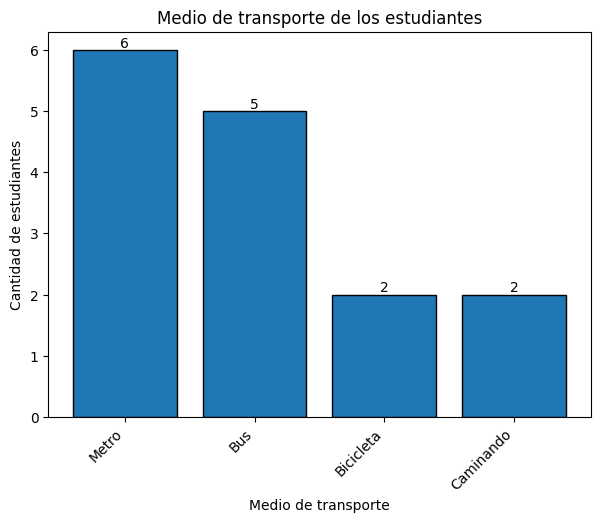

In [ ]:
categorias = tabla_nominal.index
frecuencias = tabla_nominal["Frecuencia absoluta"]

fig, ax = plt.subplots(figsize=(7,5))

barras = ax.bar(
    categorias,
    frecuencias,
    edgecolor="black"
)

ax.set_title("Medio de transporte de los estudiantes")
ax.set_xlabel("Medio de transporte")
ax.set_ylabel("Cantidad de estudiantes")

ax.bar_label(barras)

plt.xticks(rotation=45, ha="right")
plt.show()

# 6. Gráfico circular

Otra representación apropiada para una variable nominal es el **gráfico circular**.

Permite observar qué porcentaje del total corresponde a cada categoría.

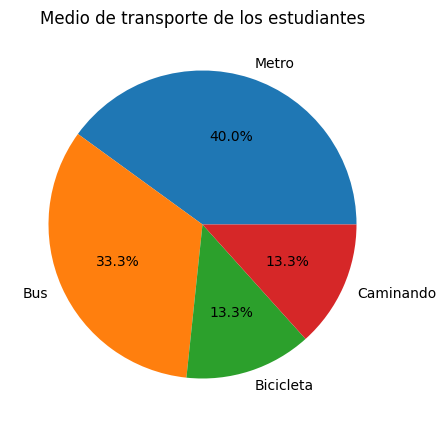

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))

ax.pie(
    tabla_nominal["Frecuencia absoluta"],
    labels=tabla_nominal.index,
    autopct="%.1f%%"
)

ax.set_title("Medio de transporte de los estudiantes")

plt.show()

# 7. Interpretación de una variable nominal

Después de construir la tabla o el gráfico podemos responder preguntas como:

- ¿cuál es la categoría más frecuente?;
- ¿cuál es la menos frecuente?;
- ¿qué porcentaje representa cada categoría?;
- ¿existe una categoría claramente predominante?

Podemos obtener directamente la categoría de mayor frecuencia con:

In [ ]:
tabla_nominal["Frecuencia absoluta"].idxmax()

'Metro'

# PARTE II: VARIABLES CUANTITATIVAS

Ahora cambiamos de tipo de variable.

Trabajaremos con la **edad de un grupo de trabajadores**.

`Edad` es una variable **cuantitativa**, porque sus valores son numéricos.

In [ ]:
df_edad = pd.DataFrame({
    "Edad": [
        19, 21, 22, 23, 24, 25, 25, 26, 27, 28,
        29, 30, 31, 31, 32, 33, 34, 34, 35, 36,
        37, 38, 39, 40, 41, 42, 43, 44, 46, 48,
        50, 53, 57
    ]
})

df_edad.head()

,Edad
0,19
1,21
2,22
3,23
4,24


# 8. Resumen inicial de una variable cuantitativa

Antes de agrupar los datos podemos observar:

- mínimo;
- máximo;
- promedio;
- mediana;
- cantidad de observaciones.

In [ ]:
df_edad["Edad"].describe()

,Edad
count,33.000000
mean,34.636364
std,9.668952
min,19.000000
25%,27.000000
50%,34.000000
75%,41.000000
max,57.000000


# 9. Rango

El rango corresponde a la diferencia entre el valor máximo y el mínimo:

$$
R=x_{\max}-x_{\min}
$$

In [ ]:
edad_min = df_edad["Edad"].min()
edad_max = df_edad["Edad"].max()
rango = edad_max - edad_min

print("Mínimo:", edad_min)
print("Máximo:", edad_max)
print("Rango:", rango)

Mínimo: 19
Máximo: 57
Rango: 38


# 10. Agrupación en intervalos con `pd.cut()`

Cuando una variable cuantitativa posee muchos valores distintos, podemos agruparla en intervalos.

Por ejemplo, si queremos **10 intervalos**:

In [ ]:
df_edad["Intervalo"] = pd.cut(
    df_edad["Edad"],
    bins=10,
    include_lowest=True,
    precision=0
)

df_edad.head()

,Edad,Intervalo
0,19,"(18.0, 23.0]"
1,21,"(18.0, 23.0]"
2,22,"(18.0, 23.0]"
3,23,"(23.0, 27.0]"
4,24,"(23.0, 27.0]"


`include_lowest=True` permite incluir el valor mínimo dentro del primer intervalo.

`precision=0` controla la cantidad de decimales mostrados en los límites de los intervalos.

# 11. Tabla de frecuencias para datos agrupados

Para cada intervalo podemos calcular:

- $f_i$: frecuencia absoluta;
- $F_i$: frecuencia absoluta acumulada;
- $h_i$: frecuencia relativa;
- $H_i$: frecuencia relativa acumulada.

In [ ]:
fi = df_edad.groupby("Intervalo", observed=True).size()
Fi = fi.cumsum()

hi = fi / fi.sum() * 100
Hi = hi.cumsum()

tabla_edad = pd.DataFrame({
    "Frecuencia absoluta": fi,
    "Frecuencia absoluta acumulada": Fi,
    "Frecuencia relativa (%)": hi,
    "Frecuencia relativa acumulada (%)": Hi
})

round(tabla_edad, 1)

,Frecuencia absoluta,Frecuencia absoluta acumulada,Frecuencia relativa (%),Frecuencia relativa acumulada (%)
Intervalo,,,,
"(18.0, 23.0]",3,3,9.1,9.1
"(23.0, 27.0]",5,8,15.2,24.2
"(27.0, 30.0]",4,12,12.1,36.4
"(30.0, 34.0]",6,18,18.2,54.5
"(34.0, 38.0]",4,22,12.1,66.7
"(38.0, 42.0]",3,25,9.1,75.8
"(42.0, 46.0]",3,28,9.1,84.8
"(46.0, 49.0]",2,30,6.1,90.9
"(49.0, 53.0]",2,32,6.1,97.0


# 12. Significado de las frecuencias

La frecuencia absoluta $f_i$ corresponde a la cantidad de observaciones del intervalo $i$.

La frecuencia absoluta acumulada es:

$$
F_i=f_1+f_2+\cdots+f_i
$$

La frecuencia relativa es:

$$
h_i=\frac{f_i}{n}
$$

y la frecuencia relativa acumulada es:

$$
H_i=h_1+h_2+\cdots+h_i
$$

En nuestra tabla $h_i$ y $H_i$ se expresan como porcentajes.

# 13. Histograma según el procedimiento de la asignatura

Utilizaremos los intervalos de la tabla como categorías y la frecuencia como altura de las barras.

El procedimiento utilizado en la asignatura es:

```python
ax.bar(categorias.astype(str), frecuencias, width=1)
```

Con `width=1` las barras quedan juntas.

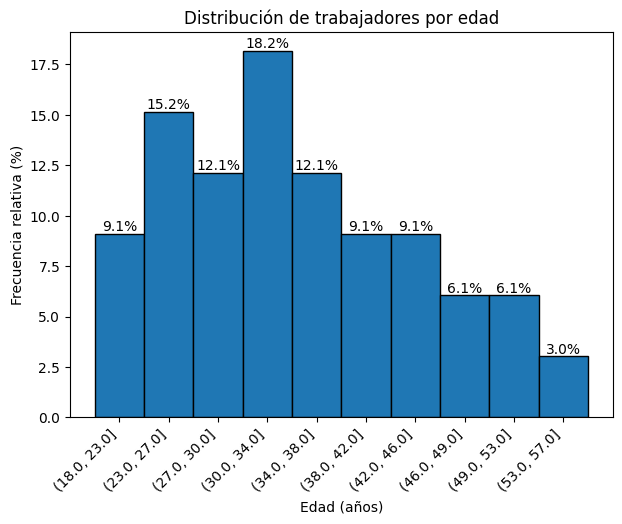

In [ ]:
# Variables
categorias_edad = tabla_edad.index
f_edad = tabla_edad["Frecuencia relativa (%)"]

# Gráfico
fig, ax = plt.subplots(figsize=(7,5))

histograma_edad = ax.bar(
    categorias_edad.astype(str),
    f_edad,
    edgecolor="black",
    width=1
)

# Personalización
ax.set_title("Distribución de trabajadores por edad")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Frecuencia relativa (%)")

ax.bar_label(histograma_edad, fmt="%.1f%%")

plt.xticks(rotation=45, ha="right")
plt.show()

# 14. Marcas de clase

La **marca de clase** es el punto medio de cada intervalo.

Si $L_i$ es el límite inferior y $L_s$ el límite superior:

$$
x_i=\frac{L_i+L_s}{2}
$$

`pandas` permite obtenerlas directamente desde los intervalos.

In [ ]:
intervalos = df_edad["Intervalo"].cat.categories

marcas_clase = intervalos.mid

marcas_clase

Index([20.5, 25.0, 28.5, 32.0, 36.0, 40.0, 44.0, 47.5, 51.0, 55.0], dtype='float64')

Podemos agregarlas a una tabla para identificar claramente el punto medio de cada intervalo.

In [ ]:
tabla_edad_con_marcas = tabla_edad.copy()
tabla_edad_con_marcas["Marca de clase"] = marcas_clase

tabla_edad_con_marcas

,Frecuencia absoluta,Frecuencia absoluta acumulada,Frecuencia relativa (%),Frecuencia relativa acumulada (%),Marca de clase
Intervalo,,,,,
"(18.0, 23.0]",3,3,9.090909,9.090909,20.5
"(23.0, 27.0]",5,8,15.151515,24.242424,25.0
"(27.0, 30.0]",4,12,12.121212,36.363636,28.5
"(30.0, 34.0]",6,18,18.181818,54.545455,32.0
"(34.0, 38.0]",4,22,12.121212,66.666667,36.0
"(38.0, 42.0]",3,25,9.090909,75.757576,40.0
"(42.0, 46.0]",3,28,9.090909,84.848485,44.0
"(46.0, 49.0]",2,30,6.060606,90.909091,47.5
"(49.0, 53.0]",2,32,6.060606,96.969697,51.0


# 15. Regla de Sturges

En algunos trabajos el número de intervalos **no viene indicado**.

Una herramienta para estimarlo es la Regla de Sturges:

$$
k=1+3.322\log_{10}(n)
$$

donde:

- $k$ es el número aproximado de intervalos;
- $n$ es la cantidad de datos.

> Si el ejercicio ya indica la cantidad de intervalos, utilizamos directamente esa cantidad.

In [ ]:
n = len(df_edad)

k_sturges = 1 + 3.322 * np.log10(n)
k = round(k_sturges)

print("Cantidad de datos:", n)
print("Resultado de Sturges:", k_sturges)
print("Número de intervalos:", k)

Cantidad de datos: 33
Resultado de Sturges: 6.044503308274343
Número de intervalos: 6


# 16. Aplicaciones con DataFrames

Además de tablas y gráficos, en la guía pueden aparecer operaciones sobre una base de datos.

Entre las más útiles están:

- ordenar;
- seleccionar los mayores valores;
- crear nuevas columnas;
- agrupar por categorías.

## Ordenar datos

In [ ]:
paises = pd.DataFrame({
    "Pais": ["A", "B", "C", "D", "E"],
    "Continente": ["Norte", "Sur", "Norte", "Sur", "Norte"],
    "Poblacion": [1200000, 850000, 2100000, 650000, 1500000],
    "Usuarios": [900000, 500000, 1800000, 400000, 1200000]
})

paises.sort_values("Poblacion", ascending=False)

,Pais,Continente,Poblacion,Usuarios
2,C,Norte,2100000,1800000
4,E,Norte,1500000,1200000
0,A,Norte,1200000,900000
1,B,Sur,850000,500000
3,D,Sur,650000,400000


## Seleccionar los mayores valores

Para obtener las observaciones con valores más altos podemos utilizar `nlargest()`.

In [ ]:
paises.nlargest(3, "Poblacion")

,Pais,Continente,Poblacion,Usuarios
2,C,Norte,2100000,1800000
4,E,Norte,1500000,1200000
0,A,Norte,1200000,900000


# 17. Crear una nueva variable

Si conocemos la cantidad de usuarios y la población, podemos calcular:

$$
\text{Porcentaje de usuarios}
=
\frac{\text{Usuarios}}{\text{Población}}\cdot100
$$

In [ ]:
paises["Porcentaje usuarios"] = (
    paises["Usuarios"] / paises["Poblacion"] * 100
)

round(paises, 1)

,Pais,Continente,Poblacion,Usuarios,Porcentaje usuarios
0,A,Norte,1200000,900000,75.0
1,B,Sur,850000,500000,58.8
2,C,Norte,2100000,1800000,85.7
3,D,Sur,650000,400000,61.5
4,E,Norte,1500000,1200000,80.0


# 18. Agrupar con `groupby()`

`groupby()` permite realizar cálculos para cada categoría.

Por ejemplo, podemos sumar población y usuarios por continente.

In [ ]:
por_continente = paises.groupby("Continente").agg({
    "Poblacion": "sum",
    "Usuarios": "sum"
})

por_continente

,Poblacion,Usuarios
Continente,,
Norte,4800000,3900000
Sur,1500000,900000


Si queremos calcular el porcentaje de usuarios de cada continente, primero sumamos los totales y después calculamos:

$$
\text{Porcentaje}
=
\frac{\text{Total de usuarios}}
{\text{Población total}}\cdot100
$$

In [ ]:
por_continente["Porcentaje usuarios"] = (
    por_continente["Usuarios"]
    / por_continente["Poblacion"]
    * 100
)

round(por_continente, 1)

,Poblacion,Usuarios,Porcentaje usuarios
Continente,,,
Norte,4800000,3900000,81.2
Sur,1500000,900000,60.0


# 19. ¿Qué gráfico utilizar?

| Tipo de variable | Ejemplos | Representación |
|---|---|---|
| Cualitativa nominal | ocupación, continente, lenguaje | Barras o circular |
| Cuantitativa agrupada | edad, porcentaje, población | Histograma por intervalos |

La idea principal es:

**primero identificar el tipo de variable y después elegir la representación.**

# 20. Resumen de comandos

| Objetivo | Comando |
|---|---|
| Primeras filas | `df.head()` |
| Resumen numérico | `df.describe()` |
| Frecuencia por categoría | `value_counts()` |
| Frecuencia por grupo | `groupby().size()` |
| Crear intervalos | `pd.cut()` |
| Frecuencia acumulada | `cumsum()` |
| Marca de clase | `.cat.categories.mid` |
| Gráfico de barras | `ax.bar()` |
| Gráfico circular | `ax.pie()` |
| Etiquetas sobre barras | `ax.bar_label()` |
| Ordenar | `sort_values()` |
| Mayores valores | `nlargest()` |
| Agrupar | `groupby()` |
| Sumar por grupo | `groupby().agg()` |

# 21. Estrategia para resolver un ejercicio

## Si la variable es nominal

1. identificar las categorías;
2. calcular frecuencias;
3. construir la tabla;
4. realizar gráfico de barras o circular;
5. interpretar.

## Si la variable es cuantitativa

1. revisar mínimo, máximo y rango;
2. determinar la cantidad de intervalos;
3. utilizar `pd.cut()`;
4. calcular $f_i$, $F_i$, $h_i$ y $H_i$;
5. obtener las marcas de clase si son necesarias;
6. construir el histograma según el formato de la asignatura;
7. interpretar.

## Si no entregan el número de intervalos

Podemos considerar la Regla de Sturges para determinar $k$.